# Lane Detection - UNet
Main reference: https://medium.com/@diazoangga/implementing-lane-detection-in-carla-using-lanenet-330d8fd8720c

In [2]:
import os
import os.path as ops

import cv2
from PIL import Image
import numpy as np
from matplotlib import pyplot as plt
import glob
import scipy
import shutil
import json

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import models, layers, Sequential

# GPU Check

In [3]:
print(tf.config.list_physical_devices('GPU'))

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [4]:
config = tf.compat.v1.ConfigProto()
config.gpu_options.per_process_gpu_memory_fraction = 0.85  # Use 80% of the GPU memory
config.log_device_placement = True  # Log device placement for debugging
session = tf.compat.v1.Session(config=config)
tf.compat.v1.keras.backend.set_session(session)

Device mapping:
/job:localhost/replica:0/task:0/device:GPU:0 -> device: 0, name: NVIDIA GeForce RTX 3050 Ti Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.6




# Split TuSimple Dataset

In [4]:
def process_tusimple_dataset(src_dir):
    # Create training directory
    traing_folder_path = ops.join(ops.split(src_dir)[0], 'training')
    os.makedirs(traing_folder_path, exist_ok=True)

    gt_image_dir = ops.join(traing_folder_path, 'gt_image')
    gt_binary_dir = ops.join(traing_folder_path, 'gt_binary_image')
    
    # Create image directory, binary and instance label directories
    os.makedirs(gt_image_dir, exist_ok=True)
    os.makedirs(gt_binary_dir, exist_ok=True)
    
    # Separate the TuSimple data set in our folder structure
    for idx, json_label_path in enumerate(glob.glob('{:s}/*.json'.format(src_dir))):
        get_image_to_folders(json_label_path, gt_image_dir, gt_binary_dir, src_dir, idx)

def get_image_to_folders(json_label_path, gt_image_dir, gt_binary_dir, src_dir, idx):
    # Get number of lines in json = number of images available
    json_line_nr = len(open(json_label_path).readlines())
    # We will only fetch a fraction of all the images.
    id_arr = np.linspace(0, json_line_nr, int(json_line_nr * 0.035)).astype(int)
    # Get dictionaries for each line in the .json file
    json_gt = [json.loads(line) for line in open(json_label_path)]
    for id, gt in enumerate(json_gt):
        if id in id_arr:
            filename = '{}_{}.png'.format(idx, id)
            fn_img_path = ops.join(gt_image_dir, filename)
            fn_bin_path = ops.join(gt_binary_dir, filename)
            if not ops.exists(fn_img_path) and not ops.exists(fn_bin_path):
                gt_lanes = gt['lanes']
                y_samples = gt['h_samples']
                raw_file = gt['raw_file']

                raw_path = ops.join(ops.join('TuLane', 'data'), raw_file)
                raw_img = cv2.imread(raw_path)

                gt_lanes_vis = [[(x,y) for (x,y) in zip(lane, y_samples) if x >=0] for lane in gt_lanes]
                img_vis = raw_img

                bin_background = np.zeros_like(raw_img)
                skip=False

                color_bw = [[255,255,255], [255,255,255], [255,255,255], [255,255,255], [255,255,255]]
                for i in range(len(gt_lanes_vis)):
                    if len(gt_lanes_vis[i]) == 0:
                        skip=False
                        break
                    else: 
                        bin_mask = cv2.polylines(bin_background, np.int32([gt_lanes_vis[i]]), isClosed=False, color=color_bw[i], thickness=5)
                        skip=False

                if skip==True:
                    print('Number of lanes is not 4!')
                else:
                    shutil.copy(raw_path, ops.join(gt_image_dir, filename))
                    cv2.imwrite(ops.join(gt_binary_dir, filename), bin_mask)

In [5]:
w_dir = os.getcwd()
src_dir = ops.join(w_dir, ops.join('TuLane','splits'))
print(src_dir)
print(ops.split(src_dir)[0])

C:\Users\racov\LaneDetectionKeras\LaneNetApproach\TuLane\splits
C:\Users\racov\LaneDetectionKeras\LaneNetApproach\TuLane


In [6]:
process_tusimple_dataset(src_dir)

# Preprocess Data & Load in RAM

In [5]:
def preprocessing(img_path, bin_path, resize=(512,256)):
    image_ds = []
    for i, image_name in enumerate(img_path):
        image = cv2.imread(image_name)
        image = Image.fromarray(image)
        image = image.resize(resize)
        image_ds.append(np.array(image, dtype=np.float32))
        
        # Show progress for loading into RAM
        if int((i % int(0.02*len(img_path)))) == 0 or i == (len(img_path) - 1):
            print(f'{i}/{len(img_path) - 1}', end = '\r' if i != (len(img_path) - 1) else '\n')
     
    mask_ds = []
    for i, image_name in enumerate(bin_path):
        image = cv2.imread(image_name, 0)
        image = Image.fromarray(image)
        image = image.resize(resize)
        label_binary = np.zeros([resize[1], resize[0]], dtype=np.uint8)
        mask = np.where(np.array(image)[:,:] != [0])
        #print(np.unique(np.array(image)))
        label_binary[mask] = 1
        mask_ds.append(np.array(label_binary, dtype=np.uint8))
        
        # Show progress for loading into RAM
        if int((i % int(0.02*len(bin_path)))) == 0 or i == (len(bin_path) - 1):
            print(f'{i}/{len(bin_path) - 1}', end = '\r' if i != (len(bin_path) - 1) else '\n')
        
    return image_ds, mask_ds

In [6]:
w_dir = os.getcwd()
src_dir = ops.join(w_dir, ops.join('TuLane','splits'))
training_fp = ops.join(ops.split(src_dir)[0], 'training')

img_fp = ops.join(training_fp, 'gt_image')
img_clahe_fp = ops.join(training_fp, 'clahe_gt_image')
bin_fp = ops.join(training_fp, 'gt_binary_image')

flag_CLAHE = True
if flag_CLAHE == True:
    img_path = glob.glob(ops.join(img_clahe_fp, "*.png"))
else:
    img_path = glob.glob(ops.join(img_fp, "*.png"))
bin_path = glob.glob(ops.join(bin_fp, "*.png"))

In [7]:
image_ds, mask_ds = preprocessing(img_path, bin_path)
print("Image Dataset size:", len(image_ds))
print("Mask Dataset size:", len(mask_ds))

1141/1141
1141/1141
Image Dataset size: 1142
Mask Dataset size: 1142


In [8]:
from sklearn.model_selection import train_test_split

tf.random.set_seed(40)
X_train, X_test, bin_train, bin_test = train_test_split(image_ds, mask_ds, test_size = 0.15, random_state=0)

In [9]:
X_train = np.array(X_train)
X_test = np.array(X_test)
bin_train = np.array(bin_train)
bin_test = np.array(bin_test)

# Fix for BinaryFocalLoss
bin_train = np.expand_dims(bin_train, axis=-1)    # Add a channel dimension
bin_test = np.expand_dims(bin_test, axis=-1)    # Add a channel dimension

print(X_train.shape)
print(X_test.shape)
print(bin_train.shape)
print(bin_test.shape)

(970, 256, 512, 3)
(172, 256, 512, 3)
(970, 256, 512, 1)
(172, 256, 512, 1)


# DNN - UNet

In [10]:
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Rescaling, Conv2D, MaxPooling2D, UpSampling2D, concatenate, Conv2DTranspose, BatchNormalization, Dropout, ReLU, Lambda

################################################################
def simple_unet_model(IMG_HEIGHT, IMG_WIDTH, IMG_CHANNELS):
#Build the model
    inputs = Input((IMG_HEIGHT, IMG_WIDTH, IMG_CHANNELS))
    #s = Lambda(lambda x: x / 255.0)(inputs)   #No need for this if we normalize our inputs beforehand
    s = inputs

    #Contraction path
    c1 = Conv2D(16, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(s)
    c1 = Dropout(0.1)(c1)
    c1 = Conv2D(16, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(c1)
    p1 = MaxPooling2D((2, 2))(c1)
    
    c2 = Conv2D(32, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(p1)
    c2 = Dropout(0.1)(c2)
    c2 = Conv2D(32, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(c2)
    p2 = MaxPooling2D((2, 2))(c2)
     
    c3 = Conv2D(64, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(p2)
    c3 = Dropout(0.2)(c3)
    c3 = Conv2D(64, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(c3)
    p3 = MaxPooling2D((2, 2))(c3)
     
    c4 = Conv2D(128, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(p3)
    c4 = Dropout(0.2)(c4)
    c4 = Conv2D(128, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(c4)
    p4 = MaxPooling2D(pool_size=(2, 2))(c4)
     
    c5 = Conv2D(256, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(p4)
    c5 = Dropout(0.3)(c5)
    c5 = Conv2D(256, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(c5)
    
    #Expansive path bin
    u6_bin = Conv2DTranspose(128, (2, 2), strides=(2, 2), padding='same')(c5)
    u6_bin = concatenate([u6_bin, c4])
    c6_bin = Conv2D(128, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(u6_bin)
    c6_bin = Dropout(0.2)(c6_bin)
    c6_bin = Conv2D(128, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(c6_bin)
     
    u7_bin = Conv2DTranspose(64, (2, 2), strides=(2, 2), padding='same')(c6_bin)
    u7_bin = concatenate([u7_bin, c3])
    c7_bin = Conv2D(64, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(u7_bin)
    c7_bin = Dropout(0.2)(c7_bin)
    c7_bin = Conv2D(64, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(c7_bin)
     
    u8_bin = Conv2DTranspose(32, (2, 2), strides=(2, 2), padding='same')(c7_bin)
    u8_bin = concatenate([u8_bin, c2])
    c8_bin = Conv2D(32, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(u8_bin)
    c8_bin = Dropout(0.1)(c8_bin)
    c8_bin = Conv2D(32, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(c8_bin)
     
    u9_bin = Conv2DTranspose(16, (2, 2), strides=(2, 2), padding='same')(c8_bin)
    u9_bin = concatenate([u9_bin, c1], axis=3)
    c9_bin = Conv2D(16, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(u9_bin)
    c9_bin = Dropout(0.1)(c9_bin)
    c9_bin = Conv2D(16, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(c9_bin)
     
    bin_seg = Conv2D(1, (1, 1), activation='sigmoid', name='bin_seg')(c9_bin)
     
    model = Model(inputs=inputs, outputs=bin_seg)
    
    return model

In [11]:
# External keras dependencies
from focal_loss import BinaryFocalLoss
def iou(y_true, y_pred):
    def f(y_true, y_pred):
        intersection = (y_true * y_pred).sum()
        union = y_true.sum() + y_pred.sum() - intersection
        x = (intersection + 1e-15) / (union + 1e-15)
        x = x.astype(np.float32)
        return x
    return tf.numpy_function(f, [y_true, y_pred], tf.float32)

In [12]:
retrain = False

if retrain == False:
    model = simple_unet_model(256, 512, 3)
    model.summary()
else:
    model_number = 1
    cwd = os.getcwd()
    load_path = ops.join(cwd, ops.join('output', 'final'))
    model_path = ops.join(load_path, os.listdir(load_path)[model_number])
    hdf5_path = ops.join(model_path, [file for file in os.listdir(model_path) if file.endswith('.hdf5')][0])
    print(hdf5_path)
    model = keras.models.load_model(hdf5_path, custom_objects={'iou':iou})
    model.summary()

Model: "model"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 input_1 (InputLayer)           [(None, 256, 512, 3  0           []                               
                                )]                                                                
                                                                                                  
 conv2d (Conv2D)                (None, 256, 512, 16  448         ['input_1[0][0]']                
                                )                                                                 
                                                                                                  
 dropout (Dropout)              (None, 256, 512, 16  0           ['conv2d[0][0]']                 
                                )                                                             

In [13]:
from tensorflow.keras.callbacks import TerminateOnNaN
from tensorflow.keras.callbacks import ModelCheckpoint
import datetime
import pickle

LR = 1e-4                      # Learning rate
EPOCHS = 200                   # Number of epochs
BS = 8                         # Number of batch size
LossWeights = 10               # Loss function weights for Binary Segmentation and Instance Segmentation
terminate = TerminateOnNaN()   # Terminate the training process if the loss reaches NaN
es = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=4)                     #Early Stopping if model overfits
log_dir = "./logs/fit/" + datetime.datetime.now().strftime("%Y%m%d-%H%M%S")               #Save path for tensorboard
tensorboard_callback = tf.keras.callbacks.TensorBoard(log_dir=log_dir, histogram_freq=1)  #Tensorboard
filepath = "./output/saved-model.hdf5"  #save path for the checkpoint function
checkpoint = ModelCheckpoint(filepath, monitor='loss', verbose=1, save_best_only=True,    #Checkpoint every epoch
                             save_weights_only=True, mode='auto', period=5)

tf.random.set_seed(40)
optimizer = tf.keras.optimizers.Adam(learning_rate=LR, decay=LR/100)   #Optimizer configuration
model.compile(optimizer=optimizer,
              loss=BinaryFocalLoss(gamma=2),
              loss_weights=LossWeights,
              metrics={'bin_seg': iou})

history = model.fit(X_train, bin_train,
                    batch_size = BS,
                    verbose=1,
                    epochs=EPOCHS,
                    validation_data=(X_test, bin_test),
                    shuffle=False,
                    callbacks=[terminate, tensorboard_callback, checkpoint])


Epoch 1/200
122/122 [==============================] - 43s 281ms/step - loss: 13.2443 - iou: 0.0074 - val_loss: 3.8767 - val_iou: 1.3274e-04
Epoch 2/200
122/122 [==============================] - 28s 226ms/step - loss: 3.9030 - iou: 7.6427e-04 - val_loss: 3.8822 - val_iou: 4.0440e-05
Epoch 3/200
122/122 [==============================] - 28s 227ms/step - loss: 3.8584 - iou: 1.8256e-04 - val_loss: 3.8823 - val_iou: 3.5074e-05
Epoch 4/200
122/122 [==============================] - 28s 227ms/step - loss: 3.8509 - iou: 2.0731e-04 - val_loss: 3.8789 - val_iou: 5.2179e-05
Epoch 5/200
122/122 [==============================] - ETA: 0s - loss: 3.8456 - iou: 2.9728e-04
Epoch 5: loss improved from inf to 3.84561, saving model to ./output\saved-model.hdf5
122/122 [==============================] - 28s 232ms/step - loss: 3.8456 - iou: 2.9728e-04 - val_loss: 3.8702 - val_iou: 1.1932e-04
Epoch 6/200
122/122 [==============================] - 28s 227ms/step - loss: 3.8351 - iou: 4.9301e-04 - val_loss

In [15]:
if not ops.exists('./output/final'):
    os.makedirs('./output/final', exist_ok=True)
np.save('./output/final/lane_4lane_6_model.npy',history.history)        #Save the training loss, acc, and meanIou
model.save('./output/final/lanenet_4lane2_6_model.hdf5')                #Save the trained weight

In [16]:
preds = model.predict(X_test[0:10])
preds.max(), preds.min()

1/1 [==============================] - 3s 3s/step


(0.81634325, 0.0)

In [1]:
## print(preds.shape)

preds2 = (preds >= (preds.max() * 0.7)).astype(int)
idx = 0
plt.subplot(3,1,1)
plt.imshow(X_test[idx]/255.)
plt.subplot(3,1,2)
plt.imshow(bin_test[idx])
plt.subplot(3,1,3)
plt.imshow(preds2[idx])

NameError: name 'preds' is not defined

In [58]:
# Vizualizarea loss-ului
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title("Loss")

NameError: name 'history' is not defined

Text(0.5, 1.0, 'IoU')

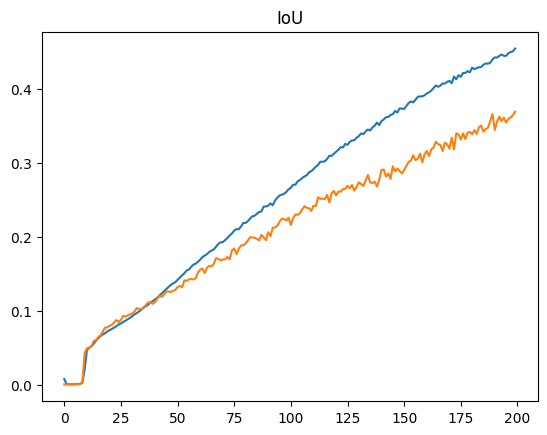

In [39]:
# Vizualizarea iou-ului
plt.plot(history.history['iou'])
plt.plot(history.history['val_iou'])
plt.title("IoU")

# Load Model

In [14]:
# Dependencies needed by Keras to load the model
from focal_loss import BinaryFocalLoss
def iou(y_true, y_pred):
    def f(y_true, y_pred):
        intersection = (y_true * y_pred).sum()
        union = y_true.sum() + y_pred.sum() - intersection
        x = (intersection + 1e-15) / (union + 1e-15)
        x = x.astype(np.float32)
        return x
    return tf.numpy_function(f, [y_true, y_pred], tf.float32)

In [15]:
cwd = os.getcwd()
load_path = ops.join(cwd, ops.join('output', 'final'))
model_path = ops.join(load_path, os.listdir(load_path)[3])
hdf5_path = ops.join(model_path, [file for file in os.listdir(model_path) if file.endswith('.hdf5')][0])
loaded_model = keras.models.load_model(hdf5_path, custom_objects={'iou':iou})

print(model_path)

C:\Users\racov\LaneDetectionKeras\LaneNetApproach\output\final\clahe_12_01_2025_200Epochs


In [16]:
preds = loaded_model.predict(X_test[100:120])
preds.max(), preds.min()

1/1 [==============================] - 10s 10s/step


(0.81917214, 0.0)

In [17]:
print(len(X_test))

172


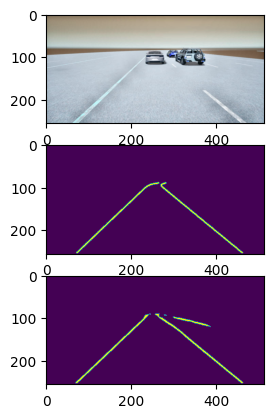

In [19]:
#### print(preds.shape)

preds2 = (preds >= (preds.max() * 0.6)).astype(int)
idx = 114
plt.subplot(3,1,1)
plt.imshow(X_test[idx]/255.)
plt.subplot(3,1,2)
plt.imshow(bin_test[idx])
plt.subplot(3,1,3)
plt.imshow(preds2[idx - 100])